In [50]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from numba import jit

# Hyperbolic CNC with Hyperbolic burden

In [51]:
def ssa_hyperbolic(x0,y0,y_div):
    del_t=0.05
    x=[x0]               #plasmid count count 
    t_x=[0]              #reaction time of fully-observed trajectory
    i=0
    y=y0
    while y<y_div:
        a=k_tr*x[i]/(1+x[i]/(y*K))
        beta=b+beta0/(1+x[i]*nu)
        t_x=np.append(t_x,[t_x[i]+del_t])
        y=y0*np.exp(beta*(t_x[i+1]-t_x[i]))   #volume at replication
        if np.random.uniform(0,1,1)<a*del_t:
            x=np.append(x,[x[i]+1])
        else:
            x=np.append(x,[x[i]])
        if y>=y_div:
            x[i+1]=x[i]
            t_x[i+1]=t_x[i]+np.log(y_div/y0)/beta
            y=y_div   #volume at replication
        y0=y
        i+=1
    #print(x,y)
    return x[-1],t_x[-1]

def simulate(init,gen,y_div):
    N=2**(gen+1)-1
    I=np.zeros(N)  #initial plasmid copy number
    F=np.zeros(N)  #final plasmid copy number
    ti=np.zeros(N)  #initial time
    tf=np.zeros(N)  #time of division
    y0=y_div/2
    I[0]=init
    ti[0]=0
    F[0],tf[0]=ssa_hyperbolic(I[0],y0,y_div)
    for i in np.arange(1,gen+1):
        index=np.arange((2**i)-1,2*((2**i)-1)+1)
        for j in range(len(index)): 
            k=index[j]
            if k%2>0:
                p=find_parent(k)
                I[k],I[k+1]=partition(F[p])
                for i in range(2):
                    ti[k+i]=tf[p]
                    F[k+i],tf_dummy=ssa_hyperbolic(I[k+i],y0,y_div)
                    tf[k+i]=tf_dummy+ti[k+i]
    return I,F,ti,tf

def partition(x):
    x0=np.random.binomial(x,0.5)
    return x0,x-x0

def find_parent(k):
    if k<3:
        p=0
    else:
        if k%2==0:
            p=int((k-2)/2)
        else:
            p=int((k-1)/2)
    return p

def find_lineage(k):
    pp=-1
    lineage=[k]
    while not(pp==0):
        pp=find_parent(lineage[-1])
        lineage=np.append(lineage,[pp])
    return lineage

def find_extinct(F):
    index=np.arange((2**gen)-1,2*((2**gen)-1)+1)
    ext=[]
    for i in index:
        if F[i]==0:
            ext=np.append(ext,[i])
    return ext

In [58]:
k_tr=1
K=1
beta0=0.4
nu=0.5
b=0

gen=3
init=6
y_div=1
y0=y_div/2
I,F,ti,tf = simulate(init,gen,y_div)

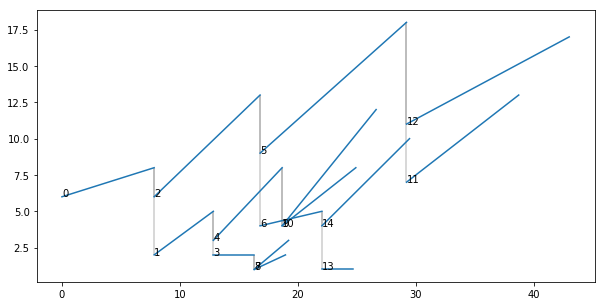

In [64]:
N=2**(gen+1)-1
f = plt.figure(figsize=(10,5))
for i in range(N):
    plt.plot([ti[i],tf[i]],[I[i],F[i]],color='C0')
    plt.text(ti[i],I[i],i)
    p=find_parent(i)
    if i>0:
        plt.vlines(tf[p],I[i],F[p],color='grey',alpha=0.4)

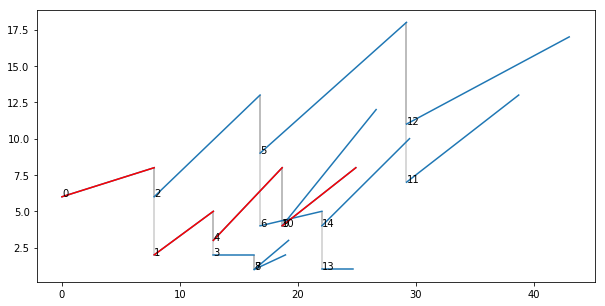

In [65]:
N=2**(gen+1)-1
f = plt.figure(figsize=(10,5))
for i in range(N):
    plt.plot([ti[i],tf[i]],[I[i],F[i]],color='C0')
    plt.text(ti[i],I[i],i)
    p=find_parent(i)
    if i>0:
        plt.vlines(tf[p],I[i],F[p],color='grey',alpha=0.4)

line=9
lineage=find_lineage(line)
for i in lineage:
    plt.plot([ti[i],tf[i]],[I[i],F[i]],color='red')
    

In [14]:
ext_line = find_extinct(F)
ext_prob = len(ext_line)/(2**gen)
print('Extinct line',ext_line)
print('Extinction prob',ext_prob)

Extinct line []
Extinction prob 0.0


In [46]:
F-I

array([ 5.,  3.,  6.,  2.,  0., 15.,  0.,  0.,  9.,  0.,  2.,  6., 11.,
        0.,  4.])